# Giai đoạn 2: Khám phá dữ liệu (EDA)

**Loại công việc: data analysis** (thống kê mô tả và trực quan hóa). Chưa phải mining, chưa phải ML.
Mục tiêu: hiểu PM2.5 thay đổi thế nào theo năm, mùa, ngày trong tuần, giờ trong ngày; nó đi kèm với điều kiện nào; và dữ liệu thiếu ảnh hưởng gì, để chuẩn bị cho bước **clustering** các đường cong ngày ở Giai đoạn 3.

**EDA** (Exploratory Data Analysis) = nhìn dữ liệu bằng biểu đồ và thống kê đơn giản *trước* khi dựng mô hình. Trong quy trình data mining (ví dụ CRISP-DM, KDD), đây là bước "data understanding": nó quyết định cách chuẩn hóa, chọn biến và chọn thuật toán ở bước sau.

Đầu vào (từ Giai đoạn 1): `../phase1/data/clean/`
- `hanoi_hourly_enriched.parquet`: một dòng một giờ (PM2.5 + thời tiết Open-Meteo/ERA5 + điểm cháy FIRMS + Tết + giãn cách).
- `hanoi_daily.parquet`: một dòng một ngày (trung bình ngày, đường cong 24 giờ `pm25_h00..h23`, thời tiết tổng hợp theo ngày).

Đầu ra: hình trong `reports/`, bảng `reports/*.csv`.

**Nhắc lại khi đọc mọi kết quả bên dưới:** đây là **mối liên hệ**, không phải nhân quả. Dữ liệu chỉ từ **một trạm** (Đại sứ quán Mỹ, quận Ba Đình), không đại diện cho cả thành phố.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)

BASE = Path(os.environ.get("HANOI_AQ_DIR", ".."))
CLEAN = BASE / "phase1" / "data" / "clean"
REPORT = Path("reports"); REPORT.mkdir(exist_ok=True)

h = pd.read_parquet(CLEAN / "hanoi_hourly_enriched.parquet")
d_all = pd.read_parquet(CLEAN / "hanoi_daily.parquet")
d = d_all[d_all["day_ok"]].copy()            # ngày đủ (>= 18/24 giờ hợp lệ)
print("giờ:", h.shape, h.index.min(), "->", h.index.max(), "| tz =", h.index.tz)
print("ngày (lịch):", len(d_all), "| ngày đủ:", len(d), "| có đường cong 24h:", int(d_all["curve_complete"].sum()))

giờ: (80592, 52) 2016-01-30 00:00:00+07:00 -> 2025-04-09 23:00:00+07:00 | tz = Asia/Ho_Chi_Minh
ngày (lịch): 3358 | ngày đủ: 2322 | có đường cong 24h: 2265


## 0. Kiểm tra chất lượng dữ liệu (nhắc lại trước khi phân tích)

Giai đoạn 1 đã làm sạch, nhưng EDA vẫn nên kiểm tra lại những điểm có thể làm lệch kết quả:
- **Múi giờ:** chỉ mục phải là `Asia/Ho_Chi_Minh`, không trùng giờ, không nhảy giờ.
- **Thiếu dữ liệu:** PM2.5 thiếu bao nhiêu; thời tiết có thiếu không (riêng `boundary_layer_height` thiếu 01/01–01/07/2024 từ nguồn).
- **Ngoại lai:** giá trị rất cao có phải sự kiện thật (pháo hoa Giao thừa, đốt rơm) hay lỗi cảm biến.

In [2]:
idx = h.index
print("tz:", idx.tz, "| trùng giờ:", idx.duplicated().sum(),
      "| bước thời gian khác 1h:", (idx.to_series().diff().dropna() != pd.Timedelta("1h")).sum())

wx = ["temperature_2m", "relative_humidity_2m", "precipitation", "surface_pressure",
      "wind_speed_10m", "wind_direction_10m", "boundary_layer_height", "shortwave_radiation", "cloud_cover"]
miss = pd.DataFrame({"tỷ lệ thiếu": h[["pm25"] + wx].isna().mean().round(3)})
print("Thời tiết Open-Meteo có trong bảng:", all(c in h.columns for c in wx))
display(miss.T)

# Ngoại lai: 15 giờ PM2.5 cao nhất và có bị gắn cờ spike không
top = h.nlargest(15, "pm25")[["pm25", "flag_spike", "tet_day", "wind_speed_10m", "boundary_layer_height"]]
display(top)
print("Số giờ gắn cờ spike:", int(h["flag_spike"].sum()), "| flatline:", int(h["flag_flatline"].sum()))

tz: Asia/Ho_Chi_Minh | trùng giờ: 0 | bước thời gian khác 1h: 0
Thời tiết Open-Meteo có trong bảng: True


,pm25,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,wind_direction_10m,boundary_layer_height,shortwave_radiation,cloud_cover
tỷ lệ thiếu,0.292,0.0,0.0,0.0,0.0,0.0,0.0,0.054,0.0,0.0


,pm25,flag_spike,tet_day,wind_speed_10m,boundary_layer_height
time,,,,,
2019-12-24 01:00:00+07:00,555.0,True,NaN,1.00,55.0
2025-03-22 16:00:00+07:00,468.0,True,NaN,2.79,1145.0
2019-01-27 02:00:00+07:00,407.0,True,-9.0,2.10,15.0
2019-10-10 02:00:00+07:00,405.0,True,NaN,1.43,15.0
2019-04-08 09:00:00+07:00,358.0,True,NaN,3.00,225.0
2019-12-13 03:00:00+07:00,340.0,True,NaN,1.91,35.0
2016-03-01 07:00:00+07:00,338.2,True,NaN,0.73,15.0
2021-12-08 04:00:00+07:00,333.0,True,NaN,2.42,20.0
2018-07-31 03:00:00+07:00,323.0,True,NaN,1.50,100.0


Số giờ gắn cờ spike: 221 | flatline: 9


**Kết quả kiểm tra (chạy 22/11/2026):** chỉ mục đúng `Asia/Ho_Chi_Minh`, không trùng, không nhảy giờ. **Thời tiết Open-Meteo đã có đủ** (đã tải lại thành công sáng 22/11), chỉ `boundary_layer_height` thiếu 5,4% (nửa đầu 2024, thiếu từ nguồn). PM2.5 thiếu 29% số giờ. Hầu hết các giờ cao nhất (300–555 µg/m³) rơi vào đêm khuya/sáng sớm với lớp biên rất thấp (15–100 m) và gió yếu, nên có thể là tích tụ thật trong lớp nghịch nhiệt hoặc nguồn đốt cục bộ gần trạm; một vài giá trị (ví dụ 468 lúc 16h ngày 22/03/2025, BLH > 1000 m) đáng nghi hơn. Vì chúng đã được gắn cờ và ta dùng median/log, ảnh hưởng tới EDA là nhỏ.

**Cách đọc:** các giá trị cao nhất cần đối chiếu với `tet_day` (0 = mùng 1 Tết; đêm Giao thừa là cuối ngày −1/đầu ngày 0) và điều kiện khí tượng (gió yếu, lớp biên thấp). Ở Giai đoạn 1 ta chỉ **gắn cờ** spike, không xóa, vì gai pháo hoa là sự kiện thật. Trong EDA ta dùng **trung vị** (median) và **thang log** ở nhiều chỗ để vài giờ cực trị không chi phối kết luận.

## 1. Phân phối PM2.5: vì sao dùng thang log

**Cách vẽ:** histogram của PM2.5 theo giờ và theo ngày, ở thang gốc và thang log.

**Vì sao:** nồng độ chất ô nhiễm thường **lệch phải** (nhiều giờ vừa phải, ít giờ rất cao) và gần với phân phối **log-normal**, vì chúng là kết quả của nhiều yếu tố nhân với nhau (phát thải × khả năng pha loãng). Lấy log làm phân phối cân đối hơn, giúp so sánh nhóm và tính tương quan ổn định hơn.

**Lựa chọn khác:** Box-Cox / Yeo-Johnson (tìm lũy thừa tối ưu thay vì cố định log), biến đổi theo **quantile** (xếp hạng, như Spearman làm ngầm), hoặc giữ thang gốc nhưng dùng thống kê bền (median, IQR).

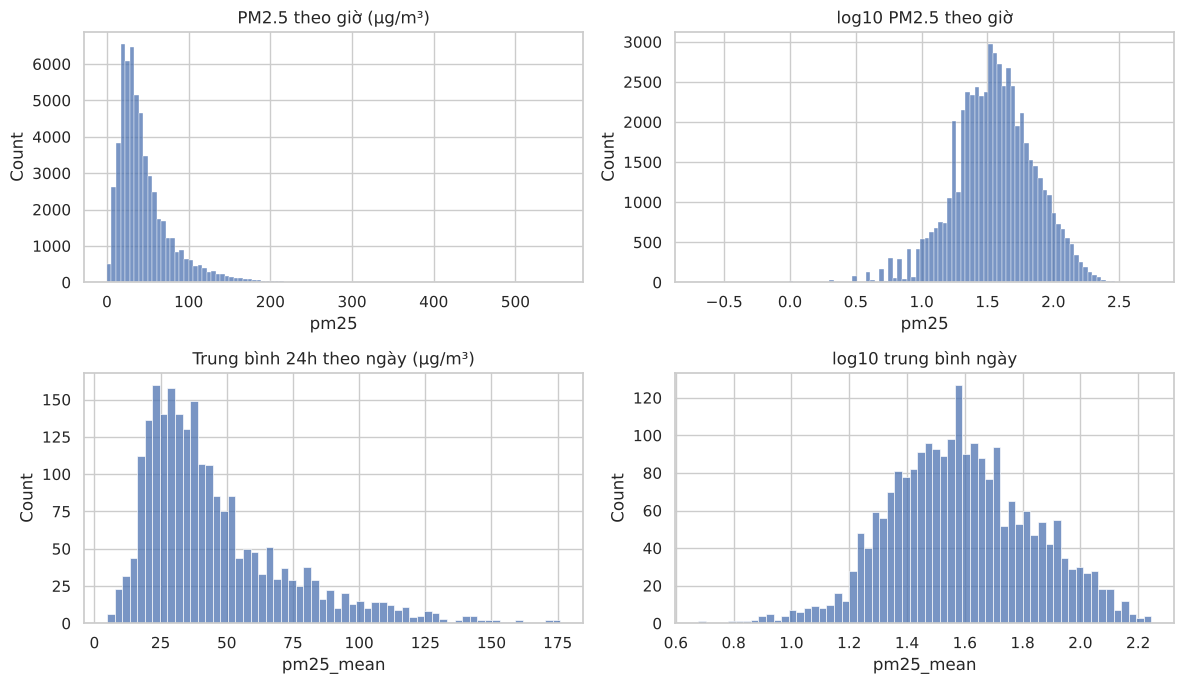

,giờ,ngày
mean,45.23,45.44
median,36.00,37.64
p95,113.00,104.02
skew (gốc),2.08,1.48
skew (log),-0.27,0.05


Giờ có PM2.5 = 0 (không lấy log được): 11


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
hp = h["pm25"].dropna(); hp_pos = hp[hp > 0]
sns.histplot(hp, bins=100, ax=ax[0, 0]); ax[0, 0].set_title("PM2.5 theo giờ (µg/m³)")
sns.histplot(np.log10(hp_pos), bins=100, ax=ax[0, 1]); ax[0, 1].set_title("log10 PM2.5 theo giờ")
sns.histplot(d["pm25_mean"], bins=60, ax=ax[1, 0]); ax[1, 0].set_title("Trung bình 24h theo ngày (µg/m³)")
sns.histplot(np.log10(d["pm25_mean"]), bins=60, ax=ax[1, 1]); ax[1, 1].set_title("log10 trung bình ngày")
plt.tight_layout(); plt.savefig(REPORT / "01_distribution.png"); plt.show()

desc = pd.DataFrame({
    "giờ": [hp.mean(), hp.median(), hp.quantile(.95), stats.skew(hp), stats.skew(np.log(hp_pos))],
    "ngày": [d.pm25_mean.mean(), d.pm25_mean.median(), d.pm25_mean.quantile(.95),
             stats.skew(d.pm25_mean), stats.skew(np.log(d.pm25_mean))]},
    index=["mean", "median", "p95", "skew (gốc)", "skew (log)"]).round(2)
display(desc)
print("Giờ có PM2.5 = 0 (không lấy log được):", int((hp == 0).sum()))

**Đọc kết quả:** skew (độ lệch) gần 0 nghĩa là cân đối. Skew của PM2.5 giờ giảm từ 2,08 xuống −0,27 sau khi lấy log (theo ngày: 1,48 → 0,05), nên ta dùng log cho các so sánh và tương quan ở dưới. Mean (45) lớn hơn median (36–38) là dấu hiệu lệch phải: khi báo cáo "mức điển hình", median đáng tin hơn mean. Có 11 giờ PM2.5 = 0 (log không xác định; trước khi gắn cờ lỗi đo ở Giai đoạn 1 là 47 giờ, và đuôi trái của log nặng hơn: skew −0,44); với đường cong ngày ta cắt dưới ở 1 µg/m³.

## 2. Xu hướng theo năm, và cái bẫy của dữ liệu thiếu

**Vấn đề:** các năm 2019, 2021, 2022, 2023 thiếu nhiều tháng (xem Giai đoạn 1). PM2.5 Hà Nội có mùa vụ rất mạnh (mùa đông cao, mùa hè thấp), nên **trung bình năm thô sẽ bị lệch** theo việc năm đó thiếu tháng nào. Ví dụ 2022 thiếu 02–10 (phần lớn mùa thấp) thì trung bình thô sẽ cao giả tạo.

**Cách xử lý ở đây:** so sánh ba cách tính
1. **Trung bình thô** của các ngày có dữ liệu.
2. **Trung bình của trung bình tháng** (mỗi tháng có ≥ 10 ngày đủ mới tính), chỉ tính nếu năm đủ 12 tháng.
3. **Chỉ số đã khử mùa** (deseasonalized): lấy log PM2.5 ngày trừ trung bình log của tháng đó trên mọi năm (khí hậu tháng), rồi lấy trung bình theo năm. Cách này cho phép so sánh năm thiếu tháng với năm đủ tháng.

**Lựa chọn khác:** mô hình hồi quy có biến năm + tháng (cùng ý tưởng nhưng có khoảng tin cậy); phân rã chuỗi thời gian STL; kiểm định xu hướng Mann-Kendall trên chuỗi tháng đã khử mùa (Theil-Sen cho độ dốc).

,ngày đủ,số tháng ≥10 ngày,TB thô,median,TB các tháng (nếu đủ 12),khử mùa (% so với TB nhiều năm)
year,,,,,,
2016,300,11,49.1,39.8,NaN,16.1
2017,287,12,42.1,34.4,41.7,-10.2
2018,240,11,41.2,33.1,NaN,-10.6
2019,206,8,52.9,42.7,NaN,0.6
2020,333,12,43.7,35.8,43.5,1.0
2021,203,8,42.8,29.6,NaN,-9.5
2022,128,4,51.6,44.7,NaN,-3.1
2023,229,9,42.1,36.6,NaN,9.0
2024,302,11,43.7,39.7,NaN,4.5


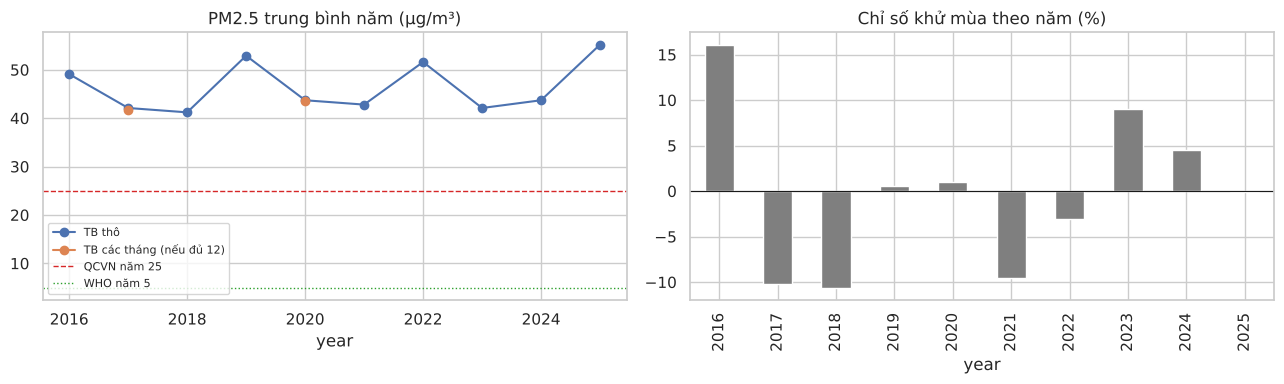

Theil-Sen: +0.0%/năm (KTC95 -1.7 .. +1.6) | Kendall tau=0.01, p=0.943 | n tháng=89


In [4]:
d["log_pm"] = np.log(d["pm25_mean"])
clim = d.groupby("month")["log_pm"].mean()
d["log_anom"] = d["log_pm"] - d["month"].map(clim)

mon = d.groupby(["year", "month"]).agg(n=("pm25_mean", "size"), m=("pm25_mean", "mean"))
mon_ok = mon[mon["n"] >= 10]
yr = pd.DataFrame({
    "ngày đủ": d.groupby("year").size(),
    "số tháng ≥10 ngày": mon_ok.groupby("year").size(),
    "TB thô": d.groupby("year")["pm25_mean"].mean(),
    "median": d.groupby("year")["pm25_mean"].median(),
    "TB các tháng (nếu đủ 12)": mon_ok.groupby("year")["m"].mean(),
    "khử mùa (% so với TB nhiều năm)": (np.exp(d.groupby("year")["log_anom"].mean()) - 1) * 100,
}).round(1)
yr.loc[yr["số tháng ≥10 ngày"] < 12, "TB các tháng (nếu đủ 12)"] = np.nan
display(yr); yr.to_csv(REPORT / "02_year_summary.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
yr[["TB thô", "TB các tháng (nếu đủ 12)"]].plot(marker="o", ax=ax[0])
ax[0].axhline(25, ls="--", c="tab:red", lw=1, label="QCVN năm 25")
ax[0].axhline(5, ls=":", c="tab:green", lw=1, label="WHO năm 5"); ax[0].legend(fontsize=8)
ax[0].set_title("PM2.5 trung bình năm (µg/m³)")
yr["khử mùa (% so với TB nhiều năm)"].plot(kind="bar", ax=ax[1], color="tab:gray")
ax[1].axhline(0, c="k", lw=.8); ax[1].set_title("Chỉ số khử mùa theo năm (%)")
plt.tight_layout(); plt.savefig(REPORT / "02_year_trend.png"); plt.show()

# Xu hướng đơn điệu trên chuỗi tháng đã khử mùa (Theil-Sen + Kendall tau)
ma = d.groupby(pd.Grouper(freq="MS"))["log_anom"].agg(["mean", "size"])
ma = ma[ma["size"] >= 10]
t_years = (ma.index - ma.index[0]).days / 365.25
ts = stats.theilslopes(ma["mean"], t_years)
tau = stats.kendalltau(t_years, ma["mean"])
print(f"Theil-Sen: {100*(np.exp(ts.slope)-1):+.1f}%/năm (KTC95 {100*(np.exp(ts.low_slope)-1):+.1f} .. {100*(np.exp(ts.high_slope)-1):+.1f}) | Kendall tau={tau.statistic:.2f}, p={tau.pvalue:.3g} | n tháng={len(ma)}")

**Đọc kết quả:** trung bình thô của 2019 (52), 2022 (52) và 2025 (55) trông như năm "tệ nhất", nhưng đó chủ yếu là do **thiếu các tháng hè sạch** (xem mục 9: cơ cấu tháng làm các năm này cao lên 8–11 µg/m³). Sau khi khử mùa, các năm chênh nhau trong khoảng ±10%, riêng 2016 cao hơn (+15%). Chuỗi tháng đã khử mùa **không có xu hướng rõ** 2016–2025: Theil-Sen +0,2%/năm, KTC95 −1,6..+1,7%. Chỉ 2017 và 2020 đủ 12 tháng để tính trung bình năm "chuẩn" (≈ 42–44 µg/m³), gần gấp đôi mức 25 của QCVN và gấp ~8 lần mức 5 của WHO.

**Lưu ý khi đọc p-value ở trên:** các tháng liên tiếp tự tương quan (autocorrelation), nên p-value thường **quá lạc quan**. Hãy xem độ dốc và khoảng tin cậy như mô tả, không phải kiểm định chặt chẽ.

## 3. Mùa và tháng

**Cách vẽ:**
- Boxplot trung bình ngày theo tháng (thang log): thấy cả mức điển hình (median) và độ phân tán.
- Heatmap năm × tháng (median): thấy cùng lúc mùa vụ, thay đổi giữa các năm và **các ô trống do thiếu dữ liệu**.

**Định nghĩa mùa:** miền Bắc có mùa khô lạnh (khoảng 11–3, gió mùa đông bắc) và mùa mưa nóng (5–9), tháng 4 và 10 chuyển tiếp. Ở đây dùng 4 nhóm cho dễ đọc: **Đông (12–2), Xuân (3–4), Hè (5–9), Thu (10–11)**. Lựa chọn khác: chia 2 mùa khô/mưa, hoặc theo mùa gặt (tháng 6 và tháng 10, gắn với đốt rơm). Cách chia mùa là một **quyết định** cần ghi vào Nhật ký vì nó sẽ được dùng lại khi mô tả cụm.

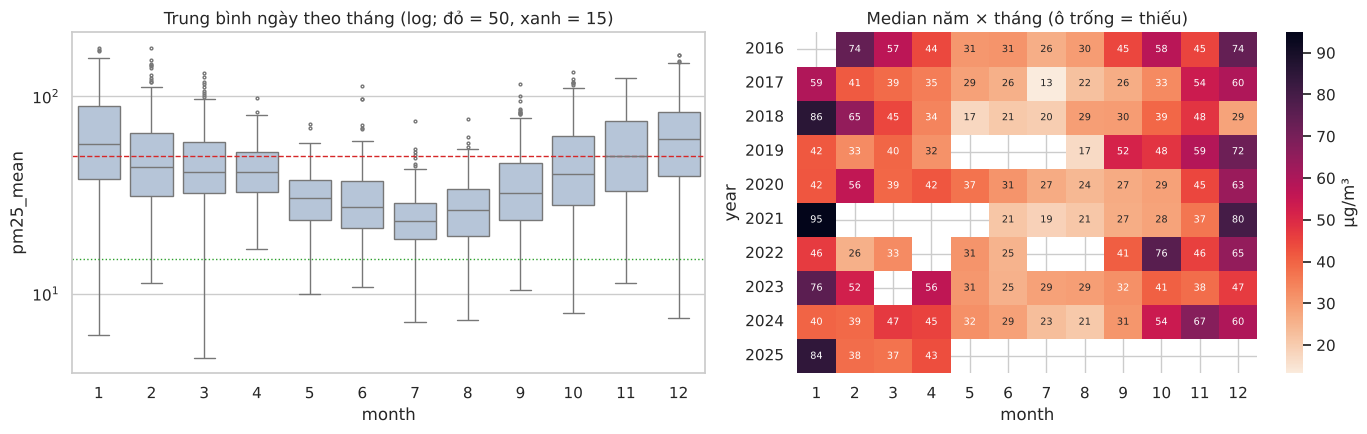

,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
Đông,632.0,62.3,34.1,6.2,36.8,53.0,81.6,176.0
Xuân,363.0,45.7,20.0,4.7,32.4,41.5,54.1,132.1
Hè,890.0,30.8,14.4,7.2,21.2,27.8,37.3,115.4
Thu,437.0,50.8,26.1,8.0,29.7,45.2,67.5,132.8


In [5]:
SEASON = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Hè", 6: "Hè", 7: "Hè", 8: "Hè", 9: "Hè", 10: "Thu", 11: "Thu"}
S_ORDER = ["Đông", "Xuân", "Hè", "Thu"]
d["season"] = pd.Categorical(d["month"].map(SEASON), S_ORDER)
h["season"] = pd.Categorical(h["month"].map(SEASON), S_ORDER)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.boxplot(data=d, x="month", y="pm25_mean", ax=ax[0], color="lightsteelblue", fliersize=2)
ax[0].set_yscale("log"); ax[0].axhline(50, ls="--", c="tab:red", lw=1); ax[0].axhline(15, ls=":", c="tab:green", lw=1)
ax[0].set_title("Trung bình ngày theo tháng (log; đỏ = 50, xanh = 15)")
hm = d.pivot_table(index="year", columns="month", values="pm25_mean", aggfunc="median")
sns.heatmap(hm, annot=True, fmt=".0f", cmap="rocket_r", ax=ax[1], cbar_kws={"label": "µg/m³"}, annot_kws={"size": 7})
ax[1].set_title("Median năm × tháng (ô trống = thiếu)")
plt.tight_layout(); plt.savefig(REPORT / "03_month_season.png"); plt.show()

display(d.groupby("season", observed=True)["pm25_mean"].describe(percentiles=[.25, .5, .75]).round(1))

**Đọc kết quả:** mùa vụ là nguồn biến thiên lớn nhất. Median ngày: Đông 53, Thu 45, Xuân 42, Hè 28 µg/m³. Tháng 12 và 1 cao nhất, tháng 7 thấp nhất. Đông và Thu cũng phân tán rộng nhất (IQR ~37–82 ở mùa Đông): cùng một mùa có cả ngày sạch lẫn ngày rất bẩn, chính là chỗ clustering có thể tìm ra các "kiểu ngày" khác nhau.

## 4. Ngày trong tuần

**Câu hỏi:** cuối tuần có sạch hơn ngày thường không (đại diện cho giao thông và sản xuất)?

**Cách làm:** so sánh **trong cùng tháng** (dùng `log_anom` đã khử mùa) để tránh việc mùa che lấp. Dùng median + khoảng tin cậy bootstrap, kiểm định **Kruskal-Wallis** (phi tham số, không cần giả định phân phối chuẩn).

**Lựa chọn khác:** ANOVA trên log (giả định chuẩn và phương sai bằng nhau), hồi quy có biến tháng × năm, so sánh ghép cặp từng tuần (thứ 7/CN với thứ 2–6 cùng tuần) để loại bỏ ảnh hưởng của thời tiết theo tuần.

In [6]:
DOW = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
rng = np.random.default_rng(0)
def boot_ci(x, f=np.mean, B=2000):
    x = np.asarray(x); bs = [f(rng.choice(x, len(x))) for _ in range(B)]
    return np.percentile(bs, [2.5, 97.5])

rows = []
for k in range(7):
    x = d.loc[d["dow"] == k, "log_anom"].values
    lo, hi = boot_ci(x)
    rows.append([DOW[k], len(x), 100*(np.exp(x.mean())-1), 100*(np.exp(lo)-1), 100*(np.exp(hi)-1)])
dw = pd.DataFrame(rows, columns=["thứ", "n", "% so với TB tháng", "KTC95 thấp", "KTC95 cao"]).set_index("thứ").round(1)
display(dw)
print("Kruskal-Wallis:", stats.kruskal(*[d.loc[d.dow == k, "log_anom"] for k in range(7)]))

# Ghép cặp trong cùng tuần: TB (T7,CN) - TB (T2..T6), chỉ tuần có đủ cả hai
wk = d.assign(wk=d.index.to_period("W-SUN"), we=d["dow"] >= 5).groupby(["wk", "we"])["log_pm"].mean().unstack().dropna()
diff = wk[True] - wk[False]
print(f"Ghép cặp theo tuần (n={len(diff)} tuần): cuối tuần {100*(np.exp(diff.median())-1):+.1f}% (median), Wilcoxon p={stats.wilcoxon(diff).pvalue:.3g}")

,n,% so với TB tháng,KTC95 thấp,KTC95 cao
thứ,,,,
T2,338,0.1,-5.2,5.3
T3,342,3.9,-1.1,9.2
T4,330,-0.5,-5.6,5.1
T5,327,-4.6,-9.8,0.8
T6,322,-0.2,-5.1,4.9
T7,332,2.4,-2.6,7.8
CN,331,-1.2,-6.5,4.6


Kruskal-Wallis: KruskalResult(statistic=np.float64(4.655737980566248), pvalue=np.float64(0.5886621724088443))
Ghép cặp theo tuần (n=346 tuần): cuối tuần -0.5% (median), Wilcoxon p=0.975


**Đọc kết quả:** **không thấy khác biệt theo ngày trong tuần** ở mức trung bình ngày: các thứ chênh nhau trong ±5%, Kruskal-Wallis p = 0,59; ghép cặp cùng tuần cho cuối tuần −0,5% (p = 0,98). Điều này gợi ý mức PM2.5 trung bình ngày ở trạm này chịu chi phối bởi khí tượng và nguồn vùng nhiều hơn là giao thông ngày thường/cuối tuần. Khác biệt nhỏ chỉ xuất hiện ở **hình dạng** (mục 5c: đỉnh sáng cuối tuần thấp hơn chút). Vì vậy biến `is_weekend` có lẽ sẽ yếu trong mô tả cụm.

## 5. Đường cong theo giờ trong ngày, theo mùa

Đây là phần quan trọng nhất cho Giai đoạn 3, vì đơn vị phân tích là **đường cong 24 giờ**.

**Cách vẽ:**
- (a) **Median** từng giờ theo mùa, có dải IQR (25–75%). Dùng median vì phân phối lệch.
- (b) **Hình dạng chuẩn hóa**: chia mỗi đường cong ngày cho trung bình ngày đó, rồi lấy median. Cách này tách *hình dạng* (đỉnh lúc nào) khỏi *mức* (cao hay thấp). Nếu hình dạng các mùa khác nhau, clustering trên đường cong chuẩn hóa sẽ có ý nghĩa.
- (c) Ngày thường vs cuối tuần.
- (d) Đường cong của lớp biên khí quyển (BLH) theo mùa: gợi ý cơ chế pha loãng. BLH thấp ban đêm thường trùng PM2.5 cao.

**Lựa chọn khác:** vẽ mean ± KTC; vẽ "spaghetti" vài trăm ngày ngẫu nhiên; heatmap giờ × tháng.

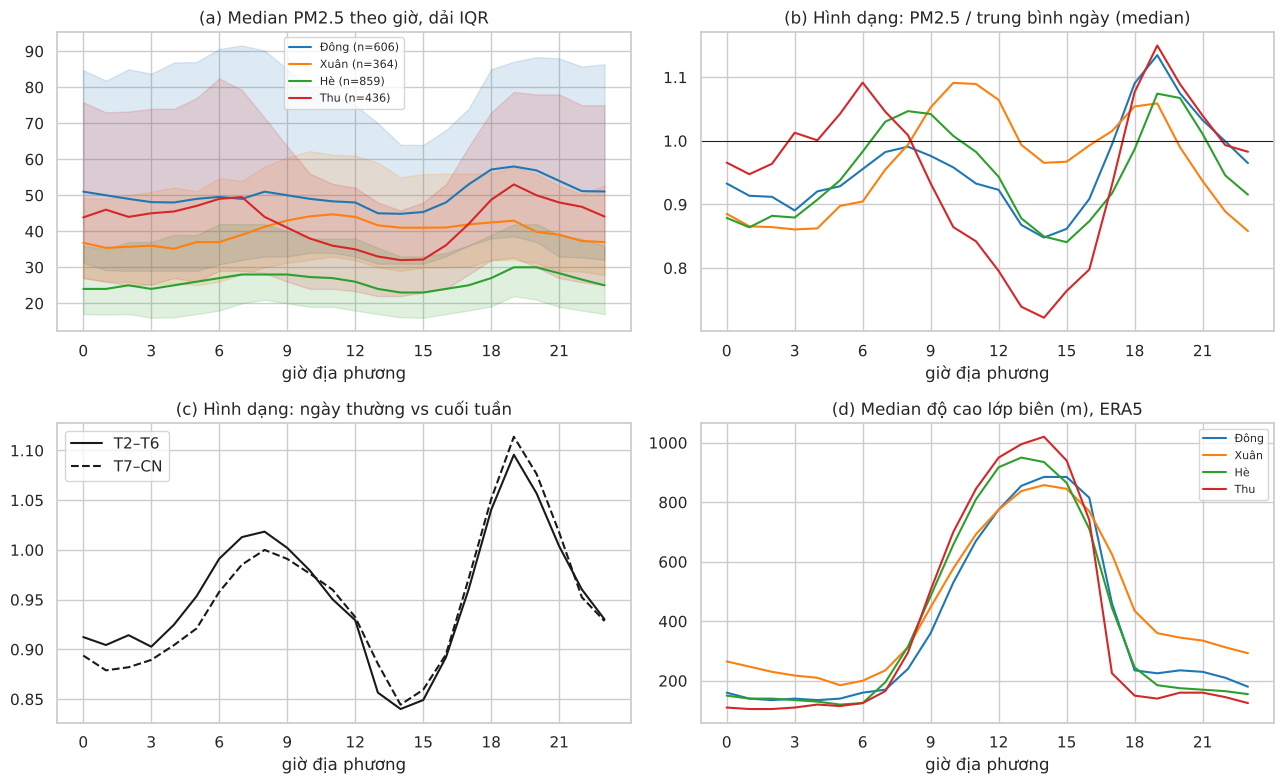

,Đông,Xuân,Hè,Thu
giờ đỉnh,19,10,19,19
giờ đáy,14,23,15,14
tỷ số đỉnh/đáy,1.34,1.27,1.28,1.59


In [7]:
HCOLS = [f"pm25_h{i:02d}" for i in range(24)]
cur = d_all.loc[d_all["curve_complete"], HCOLS + ["month", "dow"]].copy()
cur["season"] = pd.Categorical(cur["month"].map(SEASON), S_ORDER)
shape = cur[HCOLS].div(cur[HCOLS].mean(axis=1), axis=0)
pal = dict(zip(S_ORDER, sns.color_palette("tab10", 4)))

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for s in S_ORDER:
    m = cur["season"] == s
    q = cur.loc[m, HCOLS].quantile([.25, .5, .75])
    ax[0, 0].plot(range(24), q.loc[.5], label=f"{s} (n={m.sum()})", c=pal[s])
    ax[0, 0].fill_between(range(24), q.loc[.25], q.loc[.75], alpha=.15, color=pal[s])
    ax[0, 1].plot(range(24), shape.loc[m].median(), label=s, c=pal[s])
ax[0, 0].set_title("(a) Median PM2.5 theo giờ, dải IQR"); ax[0, 0].legend(fontsize=8)
ax[0, 1].axhline(1, c="k", lw=.7); ax[0, 1].set_title("(b) Hình dạng: PM2.5 / trung bình ngày (median)")
for we, lab, ls in [(False, "T2–T6", "-"), (True, "T7–CN", "--")]:
    m = cur["dow"].ge(5) == we
    ax[1, 0].plot(range(24), shape.loc[m].median(), ls=ls, label=lab, c="k")
ax[1, 0].set_title("(c) Hình dạng: ngày thường vs cuối tuần"); ax[1, 0].legend()
blh = h.groupby(["season", "hour"], observed=True)["boundary_layer_height"].median().unstack(0)
for s in S_ORDER: ax[1, 1].plot(blh.index, blh[s], c=pal[s], label=s)
ax[1, 1].set_title("(d) Median độ cao lớp biên (m), ERA5"); ax[1, 1].legend(fontsize=8)
for a in ax.flat: a.set_xticks(range(0, 24, 3)); a.set_xlabel("giờ địa phương")
plt.tight_layout(); plt.savefig(REPORT / "05_diurnal.png"); plt.show()

pk = pd.DataFrame({s: [shape.loc[cur.season == s].median().idxmax()[-2:], shape.loc[cur.season == s].median().idxmin()[-2:],
                        round(shape.loc[cur.season == s].median().max() / shape.loc[cur.season == s].median().min(), 2)]
                   for s in S_ORDER}, index=["giờ đỉnh", "giờ đáy", "tỷ số đỉnh/đáy"])
display(pk)

**Đọc kết quả:**
- Mọi mùa đều có **đỉnh tối ~19h** và **đáy chiều ~14–15h**; có đỉnh sáng phụ ~6–9h. Đáy chiều trùng lúc lớp biên cao nhất (~900–1000 m, hình d), đỉnh tối trùng lúc lớp biên sụp xuống sau 17h đồng thời giờ tan tầm. Hai cơ chế (pha loãng và phát thải) **trùng giờ nhau**, nên từ dữ liệu này không tách được phần nào do giao thông, phần nào do khí tượng.
- **Thu** có hình dạng mạnh nhất (đỉnh/đáy 1,59) với đỉnh sáng sớm ~6h, khớp với mùa gặt tháng 10 và nghịch nhiệt ban đêm trời quang. **Xuân** khác hẳn: đỉnh ~10h và buổi tối thấp hơn, BLH ban đêm cao hơn các mùa khác (mùa nồm ẩm, nhiều mây thấp).
- Cuối tuần: đỉnh sáng thấp hơn ~2–3%, đỉnh tối gần như không đổi.
- **Hệ quả cho clustering:** hình dạng khác nhau theo mùa và theo ngày, nên clustering trên đường cong đã chuẩn hóa có cơ sở.

**Lưu ý múi giờ:** Giai đoạn 1 giả định nhãn giờ của OpenAQ là *cuối giờ* và đã lùi 1 giờ (`TIME_SHIFT_H = -1`). Nếu giả định này sai, toàn bộ đường cong dịch đi 1 giờ. Điều đó không đổi kết luận về hình dạng, nhưng ảnh hưởng nếu ta gán đỉnh với "giờ cao điểm 7–8h".

## 6. Tần suất vượt ngưỡng

**Ngưỡng dùng (trung bình 24 giờ PM2.5):**

| Ngưỡng | Giá trị | Nguồn |
|---|---|---|
| WHO AQG 2021 | 15 µg/m³ (năm: 5) | WHO Global Air Quality Guidelines 2021, bảng mức hướng dẫn và mục tiêu trung gian (IT): 24h IT-1..IT-4 = 75 / 50 / 37,5 / 25 |
| QCVN 05:2023/BTNMT | 50 µg/m³ (năm: 25) | Thông tư 01/2023/TT-BTNMT, hiệu lực 12/09/2023, thay QCVN 05:2013 |
| QCVN 05:2023, lộ trình | 45 µg/m³ từ 01/01/2026 (*chưa kiểm chứng trên văn bản gốc*) | Theo các bản tóm tắt thứ cấp; cần đối chiếu bảng 1 của văn bản gốc |

Nguồn: WHO (2021) *WHO global air quality guidelines* (NCBI Bookshelf NBK574591); QCVN 05:2023/BTNMT (thuvienphapluat.vn, bản PDF trên cổng Sở TN&MT Lạng Sơn).

**Lưu ý so sánh:** QCVN áp dụng cho trạm quan trắc theo phương pháp chuẩn; trạm Đại sứ quán dùng máy BAM của Mỹ. Ở đây so sánh chỉ để tham chiếu, không phải đánh giá tuân thủ chính thức. Tần suất vượt theo năm cũng bị lệch bởi tháng thiếu, nên đưa thêm bảng theo tháng.

% ngày vượt ngưỡng, theo năm (cẩn thận: năm thiếu tháng bị lệch)


,ngày đủ,> 15 (WHO),> 25 (WHO IT-4),> 45 (QCVN 2026),> 50 (QCVN),> 75 (WHO IT-1)
year,,,,,,
2016,300,97.0,82.0,43.0,36.0,17.0
2017,287,90.0,70.0,31.0,28.0,13.0
2018,240,93.0,65.0,31.0,25.0,11.0
2019,206,98.0,89.0,48.0,43.0,20.0
2020,333,98.0,80.0,33.0,28.0,11.0
2021,203,92.0,59.0,32.0,29.0,18.0
2022,128,98.0,87.0,49.0,42.0,20.0
2023,229,100.0,78.0,35.0,27.0,7.0
2024,302,99.0,82.0,37.0,28.0,9.0


% ngày vượt ngưỡng, theo tháng (gộp mọi năm)


,> 15 (WHO),> 25 (WHO IT-4),> 45 (QCVN 2026),> 50 (QCVN),> 75 (WHO IT-1)
month,,,,,
1,98.0,94.0,63.0,58.0,33.0
2,99.0,88.0,47.0,42.0,18.0
3,98.0,89.0,43.0,35.0,14.0
4,100.0,90.0,39.0,29.0,3.0
5,94.0,68.0,11.0,5.0,0.0
6,96.0,58.0,13.0,7.0,2.0
7,89.0,41.0,4.0,2.0,1.0
8,93.0,55.0,8.0,5.0,1.0
9,94.0,68.0,27.0,21.0,6.0


Toàn bộ: {'> 15 (WHO)': np.float64(96.2), '> 25 (WHO IT-4)': np.float64(77.1), '> 45 (QCVN 2026)': np.float64(37.4), '> 50 (QCVN)': np.float64(31.4), '> 75 (WHO IT-1)': np.float64(13.9)}


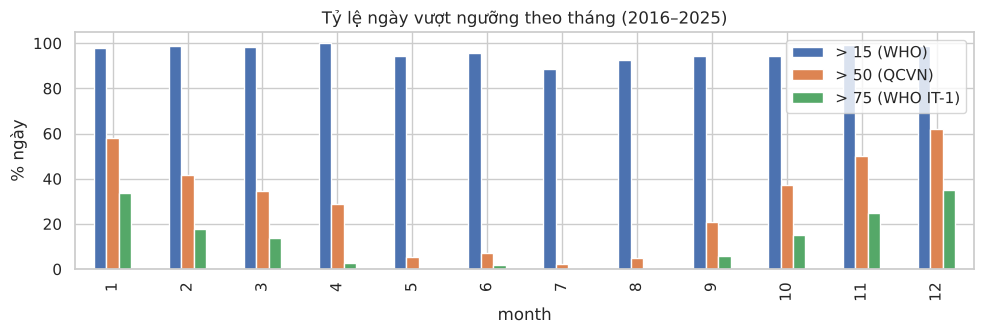

In [8]:
TH = {"> 15 (WHO)": 15, "> 25 (WHO IT-4)": 25, "> 45 (QCVN 2026)": 45, "> 50 (QCVN)": 50, "> 75 (WHO IT-1)": 75}
ex = pd.DataFrame({k: d.groupby("year")["pm25_mean"].apply(lambda x: (x > v).mean() * 100) for k, v in TH.items()})
ex.insert(0, "ngày đủ", d.groupby("year").size())
exm = pd.DataFrame({k: d.groupby("month")["pm25_mean"].apply(lambda x: (x > v).mean() * 100) for k, v in TH.items()})
print("% ngày vượt ngưỡng, theo năm (cẩn thận: năm thiếu tháng bị lệch)"); display(ex.round(0))
print("% ngày vượt ngưỡng, theo tháng (gộp mọi năm)"); display(exm.round(0))
print("Toàn bộ:", {k: round((d.pm25_mean > v).mean() * 100, 1) for k, v in TH.items()})
ex.round(1).to_csv(REPORT / "06_exceed_by_year.csv"); exm.round(1).to_csv(REPORT / "06_exceed_by_month.csv")

fig, ax = plt.subplots(figsize=(10, 3.5))
exm[["> 15 (WHO)", "> 50 (QCVN)", "> 75 (WHO IT-1)"]].plot(kind="bar", ax=ax)
ax.set_ylabel("% ngày"); ax.set_title("Tỷ lệ ngày vượt ngưỡng theo tháng (2016–2025)")
plt.tight_layout(); plt.savefig(REPORT / "06_exceed_month.png"); plt.show()

**Đọc kết quả (2.322 ngày đủ):** 96,2% số ngày vượt mức WHO 15 µg/m³; 31,4% vượt QCVN 50 µg/m³ (37,4% nếu dùng 45); 13,9% vượt mục tiêu trung gian thấp nhất của WHO (IT-1, 75). Theo tháng: tháng 12 có 62% và tháng 1 có 58% ngày vượt 50, trong khi tháng 7 chỉ 2%. Ngay cả tháng sạch nhất, 89% ngày vẫn vượt mức WHO. Tỷ lệ theo năm bị lệch theo tháng thiếu giống mục 2, đừng so trực tiếp.

## 7. Ngày đặc biệt: Tết và giãn cách COVID

**Cách làm:** so với **cùng thời điểm ở các năm khác** (không so với cả năm, vì mùa khác nhau). Với Tết, căn theo ngày âm lịch (`tet_day`, −10..+15) và dùng chỉ số khử mùa. Với giãn cách, so các ngày giãn cách với cùng ngày dương lịch ở các năm không giãn cách.

**Giới hạn:** Tết chỉ có ~9 lần, giãn cách chỉ 3 đợt (~80 ngày) → mô tả được, không đủ để kết luận chắc. Thời tiết những ngày đó cũng khác các năm khác.

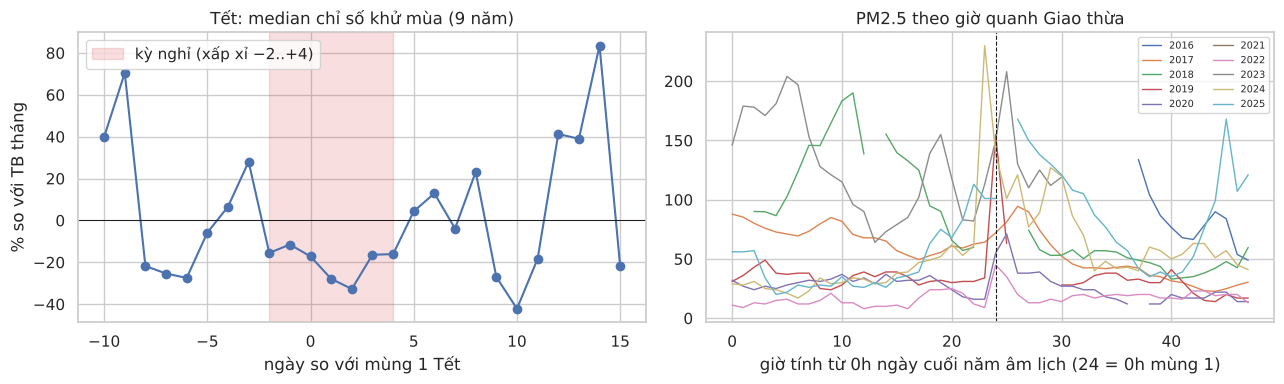

Kỳ nghỉ Tết: -18% (n=55) | các ngày ±8–30 quanh Tết: +19% (n=108) | Mann-Whitney p=0.00707


,năm,ngày giãn cách có dữ liệu,median giãn cách,median cùng ngày năm khác,n tham chiếu,khử mùa giãn cách %,khử mùa tham chiếu %
0,2020,21,42.0,41.5,109,2.9,1.7
1,2021,47,22.4,29.4,230,-19.7,3.1


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
t = d[d["tet_day"].between(-10, 15)]
g = t.groupby("tet_day")["log_anom"].agg(["median", "size"])
ax[0].plot(g.index, 100*(np.exp(g["median"])-1), marker="o")
ax[0].axvspan(-2, 4, alpha=.15, color="tab:red", label="kỳ nghỉ (xấp xỉ −2..+4)")
ax[0].axhline(0, c="k", lw=.7); ax[0].set_xlabel("ngày so với mùng 1 Tết"); ax[0].set_ylabel("% so với TB tháng")
ax[0].set_title(f"Tết: median chỉ số khử mùa ({t.year.nunique()} năm)"); ax[0].legend()

# Giờ quanh Giao thừa
gt = h[h["tet_day"].isin([-1, 0])].copy()
gt["hrel"] = ((gt["tet_day"] + 1) * 24 + gt["hour"]).astype(int)
for y, gg in gt.groupby("year"):
    ax[1].plot(gg["hrel"], gg["pm25"], lw=1, label=str(y))
ax[1].axvline(24, c="k", ls="--", lw=.8); ax[1].set_xlabel("giờ tính từ 0h ngày cuối năm âm lịch (24 = 0h mùng 1)")
ax[1].set_title("PM2.5 theo giờ quanh Giao thừa"); ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(REPORT / "07_tet.png"); plt.show()

hol = d.loc[d["is_tet_holiday"], "log_anom"]; non = d.loc[d["tet_day"].between(-30, -8) | d["tet_day"].between(8, 30), "log_anom"]
print(f"Kỳ nghỉ Tết: {100*(np.exp(hol.median())-1):+.0f}% (n={len(hol)}) | các ngày ±8–30 quanh Tết: {100*(np.exp(non.median())-1):+.0f}% (n={len(non)}) | Mann-Whitney p={stats.mannwhitneyu(hol, non).pvalue:.3g}")

# Giãn cách: so cùng ngày dương lịch ở năm khác
d["doy"] = d.index.dayofyear
rows = []
for y in [2020, 2021]:
    lk = d[(d.year == y) & d.lockdown]
    if lk.empty: continue
    ref = d[d.doy.isin(lk.doy) & ~d.lockdown & (d.year != y)]
    rows.append([y, len(lk), lk.pm25_mean.median(), ref.pm25_mean.median(), len(ref),
                 100*(np.exp(lk.log_anom.median())-1), 100*(np.exp(ref.log_anom.median())-1)])
display(pd.DataFrame(rows, columns=["năm", "ngày giãn cách có dữ liệu", "median giãn cách", "median cùng ngày năm khác", "n tham chiếu",
                                    "khử mùa giãn cách %", "khử mùa tham chiếu %"]).round(1))

**Đọc kết quả:**
- **Tết:** trong kỳ nghỉ (−2..+4), median PM2.5 thấp hơn trung bình tháng ~18%, trong khi các ngày cách Tết 8–30 ngày cao hơn ~19% (Mann-Whitney p ≈ 0,007). Nhưng đường theo ngày rất nhiễu (chỉ 9 năm), và ngày quanh Tết cũng là cao điểm mùa đông. Biểu đồ phải: **gai pháo hoa Giao thừa** quanh 0h mùng 1 (x ≈ 23–25) thấy rõ ở nhiều năm, kéo dài 1–3 giờ; riêng 2024 gai sớm hơn 1 giờ, khớp với ghi chú về giả định lệch nhãn giờ ở Giai đoạn 1.
- **Giãn cách 2021** (tháng 7–9): thấp hơn trung bình tháng ~20%, so với +4% ở cùng ngày các năm khác. **Giãn cách 2020** (tháng 4): không khác (+3% so với +2%). Hai đợt cho kết quả ngược nhau, nên không thể kết luận "giảm giao thông thì PM2.5 giảm bao nhiêu"; thời tiết và nguồn vùng của từng đợt có thể quan trọng hơn.

## 8. Tương quan với các biến đi kèm

**Cách làm:**
- **Spearman** (tương quan hạng) thay vì Pearson: không cần quan hệ tuyến tính, bền với ngoại lai, và không đổi khi lấy log.
- Tính **toàn bộ** và **trong từng mùa**. Lý do: mùa là biến gây nhiễu (confounder) mạnh. Ví dụ mùa đông vừa lạnh vừa ô nhiễm, nên tương quan nhiệt độ–PM2.5 toàn năm phần lớn chỉ phản ánh mùa. Tương quan trong mùa gần với "cùng mùa, ngày nào lạnh hơn thì có ô nhiễm hơn không".
- Dùng biến ngày: nhiệt độ, biên độ nhiệt (`t_range`, gợi ý trời quang/nghịch nhiệt ban đêm), độ ẩm, mưa, áp suất, gió, BLH, điểm cháy VIIRS (vùng đồng bằng Bắc Bộ `rrd`, toàn miền Bắc `north`, cả trễ 1 ngày).

**Lựa chọn khác:** tương quan riêng phần (partial correlation) có kiểm soát mùa; mutual information (bắt được quan hệ phi đơn điệu); mô hình GAM hoặc cây quyết định + SHAP (nhưng đó đã là ML). Ở bước EDA, Spearman theo mùa là đủ để định hướng.

**Nhắc lại:** tương quan ≠ nhân quả. Ví dụ BLH thấp và PM2.5 cao cùng xảy ra không chứng minh cái này gây ra cái kia trong dữ liệu này, dù cơ chế vật lý hợp lý.

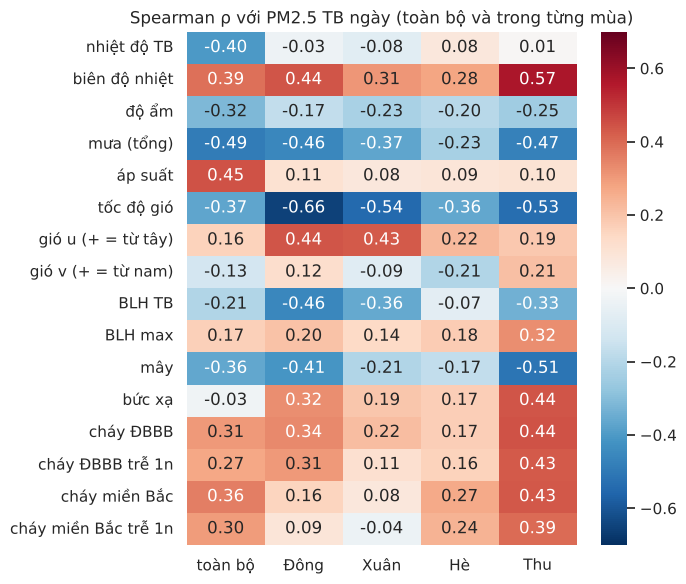

In [10]:
VARS = {"t_mean": "nhiệt độ TB", "t_range": "biên độ nhiệt", "rh_mean": "độ ẩm", "precip_sum": "mưa (tổng)",
        "pressure_mean": "áp suất", "ws_mean": "tốc độ gió", "u_mean": "gió u (+ = từ tây)", "v_mean": "gió v (+ = từ nam)",
        "blh_mean": "BLH TB", "blh_max": "BLH max", "cloud_mean": "mây", "sw_sum": "bức xạ",
        "viirs_n_rrd": "cháy ĐBBB", "viirs_n_rrd_lag1": "cháy ĐBBB trễ 1n", "viirs_n_north": "cháy miền Bắc", "viirs_n_north_lag1": "cháy miền Bắc trễ 1n"}
def sp(df):
    return pd.Series({v: stats.spearmanr(df[v], df["pm25_mean"], nan_policy="omit").statistic for v in VARS})
cor = pd.DataFrame({"toàn bộ": sp(d), **{s: sp(d[d.season == s]) for s in S_ORDER}}).rename(index=VARS)
cor.to_csv(REPORT / "08_spearman.csv")
plt.figure(figsize=(7, 6))
sns.heatmap(cor, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.7, vmax=.7)
plt.title("Spearman ρ với PM2.5 TB ngày (toàn bộ và trong từng mùa)")
plt.tight_layout(); plt.savefig(REPORT / "08_spearman.png"); plt.show()

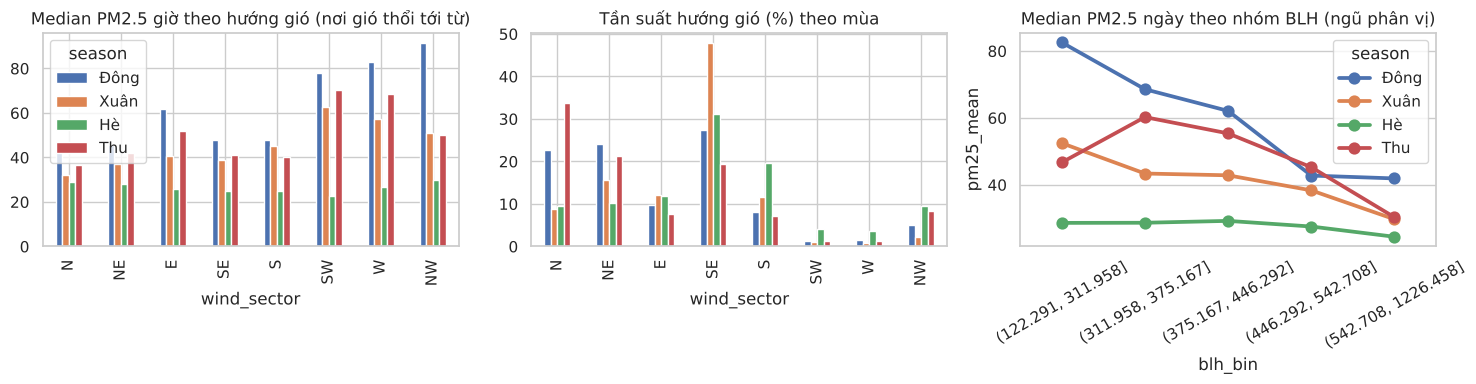

,n,median_pm,median_anom_pct
fire_bin,,,
0,233,37.2,-12.4
1–10,360,39.6,2.4
11–50,402,46.0,6.3
51–200,264,43.7,0.7
>200,137,41.2,-2.6


In [11]:
# Hướng gió: median PM2.5 theo hướng gió (giờ), trong mùa Đông và Hè; và theo nhóm tốc độ gió
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
SECT = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
ws = h.dropna(subset=["pm25"]).groupby(["season", "wind_sector"], observed=True)["pm25"].median().unstack(0).reindex(SECT)
ws.plot(kind="bar", ax=ax[0]); ax[0].set_title("Median PM2.5 giờ theo hướng gió (nơi gió thổi tới từ)")
cnt = h.dropna(subset=["pm25"]).groupby(["season", "wind_sector"], observed=True).size().unstack(0).reindex(SECT)
(cnt / cnt.sum() * 100).plot(kind="bar", ax=ax[1], legend=False); ax[1].set_title("Tần suất hướng gió (%) theo mùa")
d["ws_bin"] = pd.qcut(d["ws_mean"], 5)
d["blh_bin"] = pd.qcut(d["blh_mean"], 5)
sns.pointplot(data=d, x="blh_bin", y="pm25_mean", hue="season", estimator=np.median, errorbar=None, ax=ax[2])
ax[2].set_title("Median PM2.5 ngày theo nhóm BLH (ngũ phân vị)"); ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(REPORT / "08_wind_blh.png"); plt.show()

# Điểm cháy: chỉ mùa có đốt (VIIRS), so nhóm theo số điểm cháy
dry = d[d.month.isin([1, 2, 3, 4, 6, 10, 11])].copy()
dry["fire_bin"] = pd.cut(dry["viirs_n_north_lag1"], [-1, 0, 10, 50, 200, 1e6], labels=["0", "1–10", "11–50", "51–200", ">200"])
display(dry.groupby("fire_bin", observed=True).agg(n=("pm25_mean", "size"), median_pm=("pm25_mean", "median"),
                                                     median_anom_pct=("log_anom", lambda x: 100*(np.exp(x.median())-1))).round(1))

**Đọc kết quả tương quan:**
- **Gió yếu đi kèm ngày bẩn** là liên hệ mạnh nhất *trong mùa*: Spearman ρ = −0,66 (Đông), −0,53 (Xuân, Thu), −0,38 (Hè). Tiếp theo là **mưa** (−0,23..−0,47), **BLH trung bình thấp** (−0,46 Đông) và **biên độ nhiệt lớn** (+0,28..+0,56, gợi ý trời quang, đêm lạnh, dễ nghịch nhiệt).
- **Bài học về confounding:** nhiệt độ có ρ = −0,40 trên toàn bộ dữ liệu nhưng ≈ 0 trong từng mùa; áp suất +0,45 toàn bộ nhưng ≈ 0,1 trong mùa. Hai biến này chủ yếu "đại diện cho mùa", không mang thêm thông tin khi đã biết mùa.
- **Hướng gió:** gió hướng tây nam/tây/tây bắc đi kèm PM2.5 cao nhất (median mùa Đông 78–91 µg/m³), nhưng các hướng này **rất hiếm** (< 5% số giờ). Gió bắc/đông bắc (gió mùa đông bắc) phổ biến hơn và đi kèm mức thấp hơn. Thành phần gió u (+ = từ tây) có ρ ≈ +0,44 trong mùa Đông và Xuân.
- **Điểm cháy:** ρ +0,34 (Đông) và +0,44 (Thu) với số điểm cháy đồng bằng Bắc Bộ, nhưng bảng nhóm cho thấy sau khi khử mùa, chênh lệch nhỏ và không tăng đều (0 điểm: −12%; 11–50 điểm: +6%; > 200 điểm: −3%). Một phần tương quan có thể đến từ việc *ngày quang mây* vừa thấy được nhiều điểm cháy hơn vừa khô và lặng gió.

**Cách đọc bảng điểm cháy:** cột `median_anom_pct` đã khử mùa (so với trung bình tháng), nên phần nào bớt lẫn với việc cháy nhiều vào tháng vốn ô nhiễm. Vẫn còn nhiễu: ngày quang mây vừa *thấy* được nhiều điểm cháy hơn (vệ tinh không nhìn qua mây) vừa thường khô, ít mưa. Đây là ví dụ rõ vì sao chỉ nói "đi kèm", không nói "gây ra".

## 9. Dữ liệu thiếu 2019 / 2021 / 2022 / 2023 ảnh hưởng gì

**Câu hỏi:** các khoảng thiếu có làm **mẫu ngày bị lệch** về mùa nào không? Điều này quan trọng cho clustering: nếu mẫu thiếu mùa hè ở năm 2022, cụm "ngày sạch mùa hè" sẽ ít đại diện năm 2022, và tỷ lệ cụm theo năm sẽ không so sánh được.

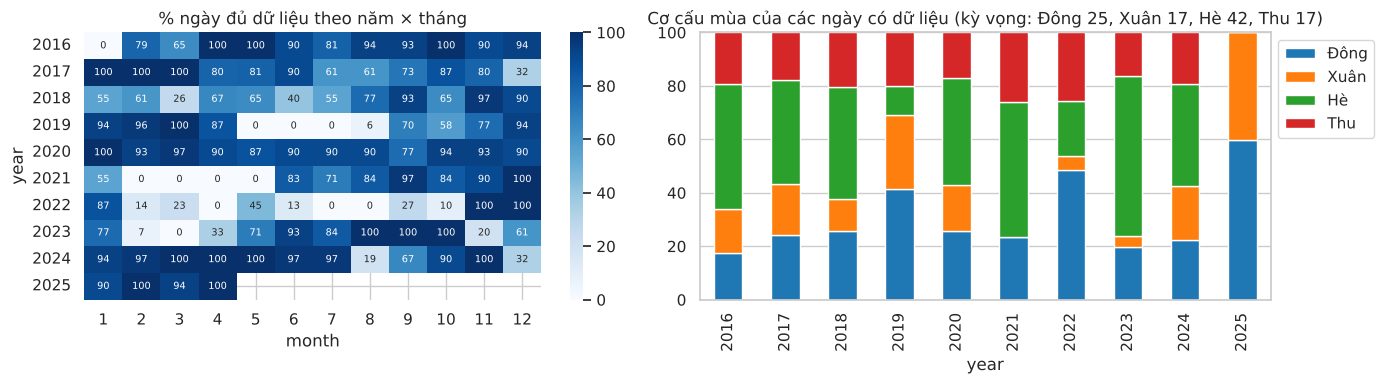

,TB khí hậu của các ngày có mặt,TB khí hậu cả năm,lệch do cơ cấu tháng (µg/m³)
year,,,
2016,42.0,44.2,-2.1
2017,44.3,44.2,0.2
2018,44.9,44.2,0.7
2019,52.5,44.2,8.3
2020,44.5,44.2,0.4
2021,44.3,44.2,0.1
2022,54.8,44.2,10.7
2023,40.8,44.2,-3.4
2024,44.1,44.2,-0.1


t_mean  rh_mean  precip_sum  ws_mean
season day_ok                                      
Đông   False     18.0     77.4         0.2      2.4
       True      18.0     78.4         0.2      2.4
Xuân   False     23.3     83.2         0.6      2.9
       True      23.7     83.1         0.5      2.7
Hè     False     28.7     83.5         3.3      2.2
       True      28.3     84.1         4.7      2.2
Thu    False     23.5     81.4         0.7      2.3
       True      24.0     78.0         0.1      2.4

In [12]:
cov = d_all.assign(ok=d_all["day_ok"]).pivot_table(index="year", columns="month", values="ok", aggfunc="mean") * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(cov, annot=True, fmt=".0f", cmap="Blues", ax=ax[0], vmin=0, vmax=100, annot_kws={"size": 7})
ax[0].set_title("% ngày đủ dữ liệu theo năm × tháng")
comp = pd.crosstab(d["year"], d["season"], normalize="index") * 100
comp.plot(kind="bar", stacked=True, ax=ax[1], color=[pal[s] for s in S_ORDER])
expected = pd.Series({s: sum(1 for m in range(1, 13) if SEASON[m] == s) / 12 * 100 for s in S_ORDER})
ax[1].set_title("Cơ cấu mùa của các ngày có dữ liệu (kỳ vọng: Đông 25, Xuân 17, Hè 42, Thu 17)")
ax[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.savefig(REPORT / "09_gaps.png"); plt.show()

# Mức lệch của trung bình thô do thiếu tháng: so TB thô với TB "đã cân lại theo tháng" (mỗi tháng có dữ liệu được tính bằng khí hậu tháng)
clim_lvl = d.groupby("month")["pm25_mean"].mean()
bias = pd.DataFrame({"TB khí hậu của các ngày có mặt": d.groupby("year")["month"].apply(lambda m: m.map(clim_lvl).mean()),
                     "TB khí hậu cả năm": clim_lvl.mean()})
bias["lệch do cơ cấu tháng (µg/m³)"] = bias.iloc[:, 0] - bias.iloc[:, 1]
display(bias.round(1))

# Thiếu có đi kèm điều kiện nào không? So thời tiết ngày thiếu và ngày đủ cùng tháng
d_all["season"] = pd.Categorical(d_all["month"].map(SEASON), S_ORDER)
cmp = d_all.groupby(["season", "day_ok"], observed=True)[["t_mean", "rh_mean", "precip_sum", "ws_mean"]].median().round(1)
display(cmp)

**Đọc kết quả:**
- Thiếu dữ liệu **không ngẫu nhiên theo mùa**: 2022 chỉ còn 4 tháng đủ, 2019 và 2021 còn 8, 2025 chỉ có 3 tháng đầu năm. Cơ cấu tháng làm trung bình thô của 2019, 2022, 2025 cao lên 8–11 µg/m³ chỉ vì thiếu mùa hè.
- Trong cùng mùa, thời tiết của ngày thiếu và ngày đủ gần như giống nhau (chênh lệch nhỏ ở mưa mùa Hè và độ ẩm mùa Thu). Thiếu dữ liệu có vẻ do vận hành/trạm hoặc thu thập của OpenAQ, **không gắn với điều kiện ô nhiễm**. Đây là suy luận từ thời tiết, chưa kiểm chứng được nguyên nhân thật.
- **Hệ quả cho clustering:** (1) gộp mọi năm để phân cụm thì ổn, nhưng **tỷ lệ cụm theo năm** không so sánh được trực tiếp; nếu cần, so theo tháng hoặc cân lại trọng số theo tháng; (2) không suy diễn "xu hướng" từ việc năm nào nhiều cụm bẩn hơn.

## 10. Chuẩn bị cho clustering (Giai đoạn 3)

Phần này là **xem trước**: phân tích cấu trúc các đường cong (PCA là kỹ thuật analysis/giảm chiều), và chạy nhanh k-means chỉ để chọn khoảng k thử. Clustering thật sự (mining) làm ở notebook sau.

**Các cách chuẩn hóa đường cong 24 giờ** (mỗi cách trả lời một câu hỏi khác nhau):

| Cách | Công thức | Cụm sẽ tách theo | Ghi chú |
|---|---|---|---|
| Gốc | x | chủ yếu là **mức** (ngày bẩn / sạch) | gần như chia theo mùa |
| Log | log x | mức, nhưng bớt bị ngày cực trị kéo | |
| Chia trung bình ngày | x / mean(x) | **hình dạng** (đỉnh sáng, đỉnh tối, phẳng…) | mức để riêng làm biến mô tả |
| z-score theo ngày | (x − mean)/sd | hình dạng, cùng biên độ | phóng đại nhiễu ở ngày rất sạch, rất phẳng |
| Log rồi trừ trung bình | log x − mean(log x) | hình dạng theo tỷ lệ | gần cách chia trung bình, ổn định hơn |

**Gợi ý:** clustering trên **hình dạng** (log − mean, hoặc x/mean), rồi dùng **mức** (TB ngày) như một biến mô tả cụm hoặc làm chiều thứ hai (clustering 2 tầng: mức × hình dạng). Như vậy cụm không chỉ lặp lại "mùa đông bẩn, mùa hè sạch" mà ta đã biết từ EDA.

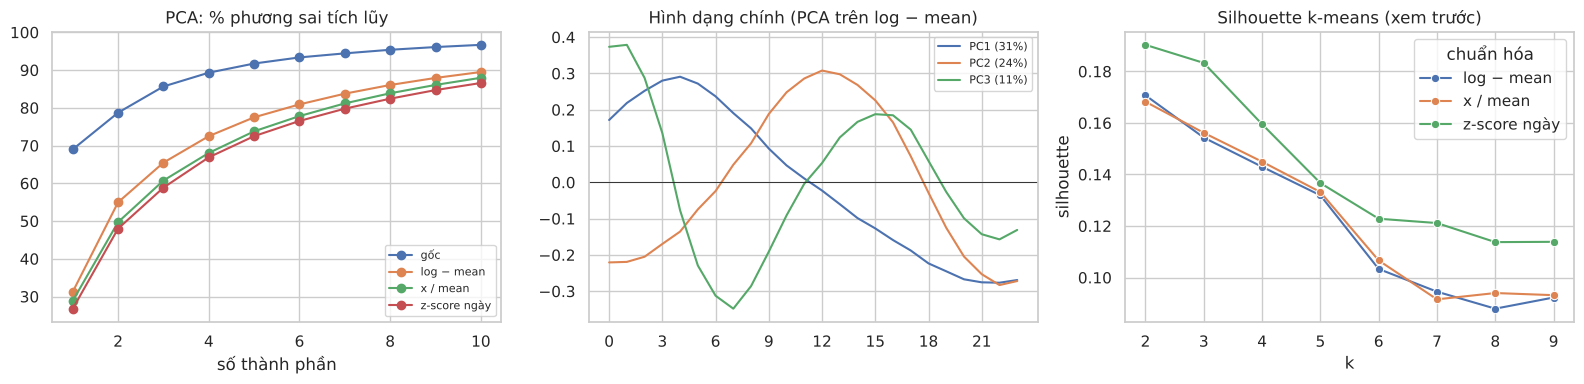

chuẩn hóa,log − mean,x / mean,z-score ngày
k,,,
2,0.171,0.168,0.190
3,0.154,0.156,0.183
4,0.143,0.145,0.160
5,0.132,0.133,0.137
6,0.103,0.107,0.123
7,0.095,0.092,0.121
8,0.088,0.094,0.114
9,0.092,0.093,0.114


In [13]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = cur[HCOLS].clip(lower=1)                 # tránh log(0)
reps = {"gốc": X.values,
        "log − mean": np.log(X).sub(np.log(X).mean(axis=1), axis=0).values,
        "x / mean": X.div(X.mean(axis=1), axis=0).values,
        "z-score ngày": X.sub(X.mean(axis=1), axis=0).div(X.std(axis=1) + 1e-9, axis=0).values}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, R in reps.items():
    p = PCA(10).fit(R); ax[0].plot(range(1, 11), np.cumsum(p.explained_variance_ratio_) * 100, marker="o", label=name)
ax[0].set_title("PCA: % phương sai tích lũy"); ax[0].set_xlabel("số thành phần"); ax[0].legend(fontsize=8)

p = PCA(3).fit(reps["log − mean"])
for i in range(3): ax[1].plot(range(24), p.components_[i], label=f"PC{i+1} ({p.explained_variance_ratio_[i]*100:.0f}%)")
ax[1].axhline(0, c="k", lw=.6); ax[1].set_title("Hình dạng chính (PCA trên log − mean)"); ax[1].legend(fontsize=8); ax[1].set_xticks(range(0, 24, 3))

res = []
for name in ["log − mean", "x / mean", "z-score ngày"]:
    R = reps[name]
    for k in range(2, 10):
        km = KMeans(k, n_init=10, random_state=0).fit(R)
        res.append([name, k, km.inertia_, silhouette_score(R, km.labels_, sample_size=1500, random_state=0)])
res = pd.DataFrame(res, columns=["chuẩn hóa", "k", "inertia", "silhouette"])
sns.lineplot(data=res, x="k", y="silhouette", hue="chuẩn hóa", marker="o", ax=ax[2]); ax[2].set_title("Silhouette k-means (xem trước)")
plt.tight_layout(); plt.savefig(REPORT / "10_cluster_prep.png"); plt.show()
display(res.pivot(index="k", columns="chuẩn hóa", values="silhouette").round(3))

**Kết quả xem trước:** trên đường cong chuẩn hóa, PCA cần ~6 thành phần để giải thích 80% phương sai (dữ liệu gốc chỉ cần 2, vì thành phần đầu chính là *mức*). Ba hình dạng chính trên log − mean: PC1 (32%) "cao về đêm/sáng sớm vs cao về tối", PC2 (23%) "bướu giữa ngày" (giống mùa Xuân), PC3 (10%) "đỉnh sáng 6–8h". Silhouette thấp (0,13–0,19) và giảm dần theo k, không có "khuỷu" rõ.

**Cách đọc:** silhouette (−1..1) đo mức các cụm tách nhau; với đường cong thời gian thực tế, giá trị 0,1–0,3 là bình thường, nghĩa là các "kiểu ngày" chuyển tiếp liên tục chứ không tách bạch. Vì vậy **không nên chọn k chỉ theo silhouette**: hãy thử k = 3–8, xem đường cong trung bình mỗi cụm có diễn giải được không, và cụm có ổn định khi chạy lại với seed/tập con khác (bootstrap stability) không.

**Lựa chọn thuật toán cho Giai đoạn 3:**
- **k-means** (Euclid): nhanh, cần chọn k, cụm hình cầu. Điểm khởi đầu tốt.
- **Hierarchical (Ward)**: cho dendrogram, thấy cấu trúc lồng nhau, không phải chọn k trước.
- **k-means với DTW** (Dynamic Time Warping, `tslearn`): cho phép đỉnh lệch 1–2 giờ vẫn coi là giống nhau. Hữu ích nếu đỉnh sáng dao động 7h–9h giữa mùa.
- **Gaussian Mixture**: cho xác suất thuộc cụm (mềm), có BIC để chọn k.
- **k-medoids**: bền hơn với ngoại lai (ngày Giao thừa).

## Tóm tắt và giới hạn

**Những gì EDA cho thấy** (tất cả là mối liên hệ):
1. PM2.5 lệch phải, gần log-normal → dùng log.
2. Mùa là yếu tố lớn nhất (median Đông 53 vs Hè 28 µg/m³); không có xu hướng năm rõ 2016–2025 sau khi khử mùa.
3. 96% số ngày vượt WHO 15; 31% vượt QCVN 50; tháng 12–1 hơn một nửa số ngày vượt 50.
4. Không có hiệu ứng ngày trong tuần ở mức trung bình ngày.
5. Đường cong ngày: đỉnh tối ~19h, đáy ~14h (trùng lớp biên cao nhất), đỉnh sáng phụ; hình dạng khác theo mùa (Thu sắc nét nhất, Xuân có đỉnh ~10h).
6. Trong cùng mùa, gió yếu, không mưa, lớp biên thấp, biên độ nhiệt lớn đi kèm ngày bẩn. Điểm cháy có liên hệ dương nhưng yếu sau khi khử mùa.
7. Kỳ nghỉ Tết thấp hơn ~18% so với trung bình tháng; giãn cách 2021 thấp hơn ~20%, giãn cách 2020 không khác.

**Gợi ý cho Giai đoạn 3 (clustering):** dùng 2.265 đường cong 24h đầy đủ (2.230 ngày sau khi bỏ ngày thiếu giờ đo thật), chuẩn hóa **log − mean** (hình dạng), để mức trung bình ngày làm biến mô tả hoặc tầng thứ hai; thử k-means và Ward với k = 4–6, đánh giá bằng khả năng diễn giải + độ ổn định bootstrap, không chỉ silhouette; cân nhắc DTW nếu đỉnh lệch giờ. Mô tả cụm bằng: mùa/tháng, gió, mưa, BLH, biên độ nhiệt, điểm cháy, Tết/giãn cách.

**Giới hạn của EDA này:**
- **Một trạm** ở Ba Đình, không đại diện cho toàn Hà Nội (ngoại thành, gần khu công nghiệp khác).
- Năm 2019, 2021, 2022, 2023 thiếu nhiều tháng; 2025 chỉ đến 09/04. Trung bình năm thô bị lệch theo cơ cấu tháng: dùng chỉ số khử mùa khi so năm.
- Thời tiết là **tái phân tích ERA5** (ô lưới ~25 km), không phải đo tại trạm; BLH thiếu nửa đầu 2024.
- Điểm cháy FIRMS chỉ trong lãnh thổ Việt Nam, bị mây che; là chỉ số tương đối.
- Giả định lệch nhãn giờ −1h chưa chắc chắn (kiểm tra pháo hoa: 3/4 năm khớp).
- Mọi kết quả là **mối liên hệ**. Mùa là biến gây nhiễu mạnh: luôn so sánh trong cùng mùa hoặc sau khi khử mùa.

**Quyết định cần ghi vào "Nhật ký quyết định" trong brief:** cách chia mùa; dùng log/chỉ số khử mùa khi so năm; ngưỡng tham chiếu (15 / 50, và 45 từ 2026 nếu xác nhận); cách chuẩn hóa đường cong cho clustering.